# 03　OFDM：一致性判定

`02_OFDM_demod` 已经把 OFDM 解出来，本册只做一件事：**拿实测指标对照门限**，给出 PASS / FAIL。

| 判据 | 门限 | 离线仿真值（SNR 30 dB） |
|---|---|---|
| 误码 | 0 / 9216 | 0 |
| EVM max | ≤ 8% | 1.5% |
| 判决余量 min | ≥ 0.85 | 0.95 |
| 残余频偏 | \|Δf\| < 800 Hz | 几十~几百 Hz |

门限由仿真留 2~5 倍余量：板上多了 DAC/ADC 量化、环回损耗和时钟抖动，指标会变差，
但不该跨一个量级。门限写在 `mod_cases.LIM`（`ofdm_case.LIM` 是同一份引用），改动只有一处。

> OFDM 的 EVM 与单载波案例不能直接横比：这里每个子载波都经过一次 LS 均衡，
> 环回幅度响应被除以 H。EVM 主要由噪声与残余相噪决定，链路增益不敏感。


## 1　复算并判定

In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / ofdm_dsp / ofdm_case / 全部 .npz 都在这里
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "OFDM"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C
import ofdm_dsp as O
import ofdm_case as OC

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

print("ofdm_dsp :", O.__file__)
print("ofdm_case:", OC.__file__)
print("案例     : %s（OFDM，%d 子载波 / %d bit 每帧）"
      % (CASE, len(O.K_USED), O.N_BITS))
print("库目录   :", LIB)
import qpsk_dsp as D

print("qpsk_dsp :", D.__file__)
print("抓包文件 :", CAP_NPZ)


ofdm_dsp : /home/xilinx/modulation/ofdm_dsp.py
ofdm_case: /home/xilinx/modulation/ofdm_case.py
案例     : OFDM（OFDM，106 子载波 / 1024 bit 每帧）
库目录   : /home/xilinx/modulation
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
抓包文件 : /home/xilinx/modulation/mod_01_OFDM.npz


In [2]:
if not os.path.exists(CAP_NPZ):
    raise FileNotFoundError("缺 %s —— 先跑 %02d_%s_tx_rx.ipynb"
                            % (CAP_NPZ, N_TX, CASE))

r = OC.load_and_demod(CAP_NPZ)
ok, det = OC.verdict(r)
m, sync = r["metrics"], r["sync"]

print("%-6s %-5s  %s" % (CASE, "PASS" if ok else "FAIL", det))
print()
rows = [
    ("误码", "%d / %d" % (m["err"], m["tot"]), "0",
     m["err"] == 0),
    ("EVM max", "%.2f %%" % m["evm_max"], "≤ %.1f %%" % OC.LIM["evm_max"],
     m["evm_max"] <= OC.LIM["evm_max"]),
    ("判决余量 min", "%.3f" % m["margin_min"],
     "≥ %.2f" % OC.LIM["margin_min"],
     m["margin_min"] >= OC.LIM["margin_min"]),
    ("残余频偏", "%+.0f Hz" % m["cfo"], "±800 Hz",
     abs(m["cfo"]) < 800.0),
]
print("  %-14s %-12s %-12s %s" % ("判据", "实测", "门限", "结果"))
print("  " + "-" * 54)
for name, got, lim, good in rows:
    print("  %-14s %-12s %-12s %s" % (name, got, lim, "PASS" if good else "FAIL"))
print()
print("  共轭方向 %s，训练相关峰 %d 个"
      % ("是" if sync["conjugated"] else "否", len(sync["peaks"])))


OFDM   PASS   BER 0/9216，EVM max 1.55%（≤8.0），余量 min 0.959（≥0.85）

  判据             实测           门限           结果
  ------------------------------------------------------
  误码             0 / 9216     0            PASS
  EVM max        1.55 %       ≤ 8.0 %      PASS
  判决余量 min       0.959        ≥ 0.85       PASS
  残余频偏           -10 Hz       ±800 Hz      PASS

  共轭方向 是，训练相关峰 18 个


**应该看到**：第一行 `PASS`，下面每一行都是 `PASS`，`共轭方向 是`。

若有 FAIL，先看是哪一条：

| 失败项 | 优先检查 |
|---|---|
| 误码 ≠ 0 而 EVM 正常 | 同步（共轭方向、峰个数）或补零位置；看 02 第 2 节打印 |
| EVM 偏大且星座弥散 | 01 的削顶点数、段内 rms；ADC 是否只回 I 通道 |
| 余量低但误码为 0 | 星座被压缩 / 噪声偏大；看 (c) 判决边界附近的点 |
| 残余频偏大 | 两侧 NCO 是否同为 1000 MHz；LMK 是否真的 256 MHz |


## 2　指标图

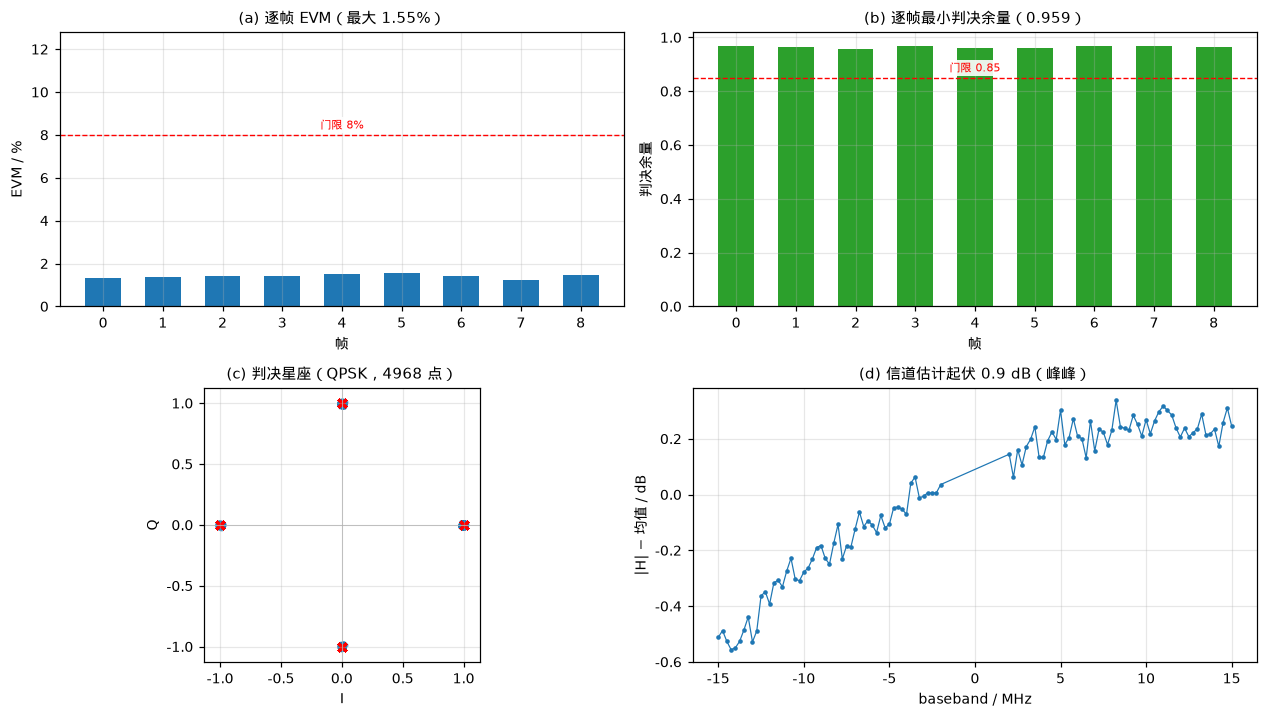

In [3]:
evm_f = np.array([q["evm"] for q in r["res"]])
mar_f = np.array([q["margin"] for q in r["res"]])
x = np.arange(len(evm_f))


def _note(a, y, text):
    """把门限文字标在虚线上方居中的空白处，替代图例（图例框会压在柱子上）。"""
    a.annotate(text, xy=(0.5, y), xycoords=("axes fraction", "data"),
               xytext=(0, 2.5), textcoords="offset points",
               ha="center", va="bottom", fontsize=7, color="r",
               bbox=dict(fc="white", ec="none", pad=1.5, alpha=0.9))


fig, ax = plt.subplots(2, 2, figsize=(11.6, 6.6))

ax[0, 0].bar(x, evm_f, width=0.6, color="C0")
ax[0, 0].axhline(OC.LIM["evm_max"], color="r", ls="--", lw=0.9)
ax[0, 0].set_ylim(0, OC.LIM["evm_max"] * 1.6)
ax[0, 0].set_xticks(x)
ax[0, 0].set_xlabel("帧"); ax[0, 0].set_ylabel("EVM / %")
ax[0, 0].set_title("(a) 逐帧 EVM（最大 %.2f%%）" % m["evm_max"])
_note(ax[0, 0], OC.LIM["evm_max"], "门限 %.0f%%" % OC.LIM["evm_max"])

ax[0, 1].bar(x, mar_f, width=0.6, color="C2")
ax[0, 1].axhline(OC.LIM["margin_min"], color="r", ls="--", lw=0.9)
ax[0, 1].set_ylim(0, 1.02)
ax[0, 1].set_xticks(x)
ax[0, 1].set_xlabel("帧"); ax[0, 1].set_ylabel("判决余量")
ax[0, 1].set_title("(b) 逐帧最小判决余量（%.3f）" % m["margin_min"])
_note(ax[0, 1], OC.LIM["margin_min"], "门限 %.2f" % OC.LIM["margin_min"])

Y = np.concatenate([q["Y"] for q in r["res"]])
ideal = np.concatenate([q["ideal"] for q in r["res"]])
ax[1, 0].scatter(Y.real, Y.imag, s=4, alpha=0.35, color="C0")
ax[1, 0].scatter(ideal.real, ideal.imag, s=26, marker="x", color="r")
ax[1, 0].axhline(0, color="0.7", lw=0.5)
ax[1, 0].axvline(0, color="0.7", lw=0.5)
ax[1, 0].set_xlabel("I"); ax[1, 0].set_ylabel("Q")
ax[1, 0].set_aspect("equal")
ax[1, 0].set_title("(c) 判决星座（QPSK，%d 点）" % len(Y))

H = r["res"][0]["H"]
kk = O.K_USED
hdb = 20 * np.log10(np.abs(H[kk % O.N]) + 1e-12)
ax[1, 1].plot(kk * O.SPACING / 1e6, hdb - np.mean(hdb), ".-", ms=4, lw=0.8)
ax[1, 1].set_xlabel("baseband / MHz"); ax[1, 1].set_ylabel("|H| − 均值 / dB")
ax[1, 1].set_title("(d) 信道估计起伏 %.1f dB（峰峰）" % np.ptp(hdb))

plt.tight_layout()
plt.show()


## 3　结论与排错

OFDM（1024 点 FFT / QPSK 子载波）的判定全 PASS 说明：训练符号同步与 CFO 估计在 1000 MHz NCO 环回下成立，
逐子载波 LS 信道估计 + 导频公共相位纠正足以把 92 个数据子载波全部判对，环回没有引入不可逆的频谱翻转
（共轭方向判对）或带内滚降。

| 症状 | 检查顺序 |
|---|---|
| 星座整体旋转 | CFO 校正符号/量程；共轭方向；两侧 NCO |
| 部分子载波持续错 | 该子载波被干扰或 H 估计异常；看 02 的 (b) 和 03 的 (d) |
| EVM 逐帧上升 | 时钟漂移或温度；CFO 是否只估了一次 |
| (d) 边缘起伏大 | ±15 MHz 已接近模拟通道滚降，减小 `K_MAX` 或加衰减器 |
| 余量低但误码 0 | 噪声偏大；看段内 rms 和 ADC 位数占用 |

> 与单载波案例一样，本册只读 `.npz`，断电重启后可以直接跑；要重抓数据回 `01_OFDM_tx_rx`。
